# Lateral PML at oblique incidence

The lateral PML ([docs/PML.md](../docs/PML.md)) turns the periodic solver into a solver for **isolated** structures. An oblique plane wave cannot cross a lateral PML undistorted, so by default (`Config.pml_formulation="scattered"`) the field is split as $\mathbf E = \mathbf E_\text{inc} + \mathbf E_s$:

- $\mathbf E_\text{inc}$ is the exact plane-wave solution of the **background stack** (every patterned layer filled with its void medium);
- $\mathbf E_s$ is solved with RCWA + PML, driven by a source $\Delta\varepsilon\,\mathbf E_\text{inc}$ localized in the structure. It is purely outgoing, which is what the PML absorbs.

This notebook uses a dielectric ridge ($\varepsilon = 4$, width 0.5, height 0.3) in air on glass ($\varepsilon = 2.25$) at wavelength 0.8. The ridge is uniform along $y$ and the PML acts along $x$:

1. checks the scattered-field formulation against the total-field one at normal incidence;
2. compares the specular scattering amplitude at $\theta = 0.4$ with a large periodic supercell;
3. sweeps the angle of incidence: scattered power, extinction, specular amplitude;
4. shows the scattered field on the substrate face.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

from metarcwa import (Config, IsotropicMedium, Lattice, Layer, Model, Observables, PML, Solver,
                      Source, Stack)
from metarcwa.model.nn_helpers import CallableModule

dtype = torch.float64
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_default_dtype(dtype)

WL, EPS_RIDGE, W_RIDGE, H_RIDGE, EPS_SUB = 0.8, 4.0, 0.5, 0.3, 2.25


def medium(eps):
    # Constant-permittivity isotropic medium.
    return IsotropicMedium(CallableModule(lambda wl: torch.full_like(wl, eps, dtype=torch.complex128)))


def ridge(L):
    # Centred ridge of width W_RIDGE along x, uniform along y.
    def shape_fn(lattice, nx, ny):
        x = ((torch.arange(nx, dtype=dtype) + 0.5) / nx - 0.5) * L
        return (x.abs() < W_RIDGE / 2).to(dtype)[None, :].expand(ny, nx)
    return CallableModule(shape_fn)


def model(L, theta=0.0, pml=None):
    layer = Layer(medium_solid=medium(EPS_RIDGE), medium_void=medium(1.0),
                  shape_fn=ridge(L), thickness=H_RIDGE)
    stack = Stack(incidence=medium(1.0), layers=[layer], transmission=medium(EPS_SUB),
                  lattice=Lattice.rectangular(L, 0.5), pml=pml)
    return Model(stack, Source(wavelength=torch.tensor(WL), theta=theta))


def config(L, **kw):
    # About 5 harmonics per unit cell length; a 2D problem (n = 0, uniform along y).
    m = round(5 * L)
    base = dict(dtype=dtype, device=device, nx=max(8 * m, 64), ny=4, m=m, n=0,
                truncation="rectangular", factorization=None)
    base.update(kw)
    return Config(**base)

## 1. Normal incidence: scattered vs total field

At normal incidence the total field can be solved directly (the incident wave has no tilt along the PML axis), so both formulations must agree to round-off. `Observables.jones` returns the specular Jones matrix: in the scattered formulation, background plus the cell average of the scattered field.

In [2]:
L = 4.0
for form in ("total", "scattered"):
    obs = Observables(Solver(model(L, pml=PML(width=(0.75, 0.0))), config(L, pml_formulation=form)).run())
    print(f"{form:9s}  r_ss = {complex(obs.jones('reflection')[..., 0, 0]):.12f}"
          f"   t_pp = {complex(obs.jones('transmission')[..., 1, 1]):.12f}")

total      r_ss = -0.062113322565+0.135326256862j   t_pp = -0.521603508121+0.373827477864j
scattered  r_ss = -0.062113322565+0.135326256862j   t_pp = -0.521603508121+0.373827477864j


## 2. Oblique incidence vs a large periodic supercell

At $\theta = 0.4$ along the PML axis only the scattered formulation applies. For an isolated ridge, the scattered part of the specular amplitude scales as $1/L$: $L\,(J - J_\text{bg})$ is the specular scattering amplitude per unit length, independent of the cell. A periodic array (no PML) with a large period $L_p$ gives the same quantity as $L_p\,(J_{00} - J_\text{bg})$ when the coupling between ridges becomes negligible. The two must converge to the same limit.

PML L=16:       0.2319-0.8197j
periodic Lp=24: 0.2310-0.8198j


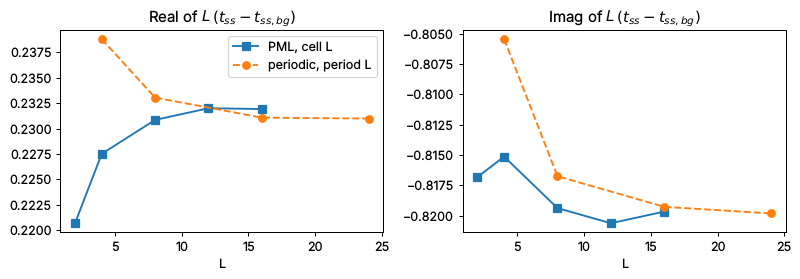

In [3]:
theta = 0.4
cells = [2.0, 4.0, 8.0, 12.0, 16.0]
periods = [4.0, 8.0, 16.0, 24.0]

pml_amp, per_amp = [], []
for L in cells:
    obs = Observables(Solver(model(L, theta, PML(width=(min(0.2 * L, 2.0), 0.0))), config(L)).run())
    pml_amp.append(complex(L * (obs.jones("transmission") - obs.background_jones("transmission"))[..., 0, 0]))
J_bg = obs.background_jones("transmission")
for Lp in periods:
    obs_p = Observables(Solver(model(Lp, theta), config(Lp)).run())
    per_amp.append(complex(Lp * (obs_p.jones("transmission") - J_bg)[..., 0, 0]))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, part in zip(ax, ("real", "imag")):
    a.plot(cells, [getattr(z, part) for z in pml_amp], "s-", label="PML, cell L")
    a.plot(periods, [getattr(z, part) for z in per_amp], "o--", label="periodic, period L")
    a.set_xlabel("L")
    a.set_title(f"{part.capitalize()} of $L\\,(t_{{ss}} - t_{{ss,bg}})$")
ax[0].legend()
plt.tight_layout()
plt.show()
print("PML L=16:      ", f"{pml_amp[-1]:.4f}")
print("periodic Lp=24:", f"{per_amp[-1]:.4f}")

## 3. Angle sweep: scattered power and extinction

`scattered_power(kind)` is the Poynting flux of the scattered field through the incidence-side (`"reflection"`) or substrate-side (`"transmission"`) face, normalized to the incident power on one cell. Multiplied by $L$ it is a scattering cross section per unit length (in units of length). `extinction()` is the power taken from the incident wave (scattered + absorbed), from the interference term between incident and scattered fields. The ridge is lossless, so extinction must equal the total scattered power. Both are evaluated in a finite cell, so they agree only up to a residual from the lateral tails of the scattered field; it shrinks with the cell size and is largest near grazing incidence (relative residual ~1e-2 at $L = 8$, ~3e-3 at $L = 24$ for $\theta = 1.2$). The angles are batched in one solver run.

max relative |extinction - total scattered| = 0.014891644837365424


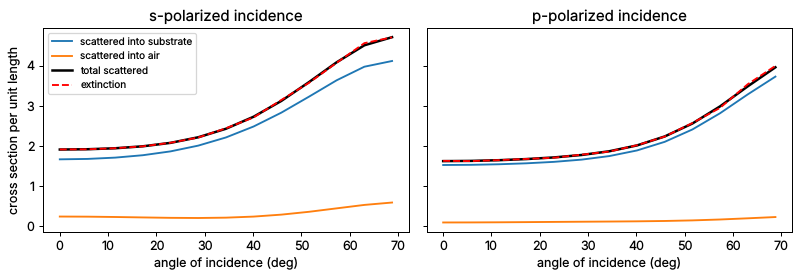

In [4]:
L = 16.0
thetas = torch.linspace(0.0, 1.2, 13)
obs = Observables(Solver(model(L, thetas, PML(width=(3.0, 0.0))), config(L)).run())
sr = L * obs.scattered_power("reflection").reshape(-1, 2)
st = L * obs.scattered_power("transmission").reshape(-1, 2)
ext = L * obs.extinction().reshape(-1, 2)

deg = torch.rad2deg(thetas)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for a, k, pol in zip(ax, (0, 1), ("s", "p")):
    a.plot(deg, st[:, k], label="scattered into substrate")
    a.plot(deg, sr[:, k], label="scattered into air")
    a.plot(deg, (sr + st)[:, k], "k-", lw=2, label="total scattered")
    a.plot(deg, ext[:, k], "r--", label="extinction")
    a.set_xlabel("angle of incidence (deg)")
    a.set_title(f"{pol}-polarized incidence")
ax[0].set_ylabel("cross section per unit length")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("max relative |extinction - total scattered| =", float(((ext - sr - st) / ext).abs().max()))

## 4. Scattered field on the substrate face

`scattered_field(kind)` reconstructs the scattered tangential fields on the real-space grid. Below is $|E_{s}|^2$ just inside the substrate for s-polarized incidence at two angles. The field decays inside the PML (shaded).

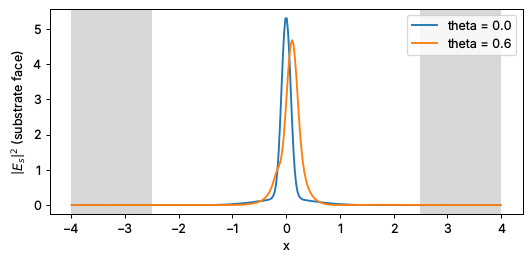

In [5]:
L, w = 8.0, 1.5
fig, ax = plt.subplots(figsize=(6, 3))
for th in (0.0, 0.6):
    obs = Observables(Solver(model(L, th, PML(width=(w, 0.0))), config(L)).run())
    f = obs.scattered_field("transmission")[..., :2, 0, 0, :].reshape(2, -1)   # (Ex, Ey), s-pol, row y = 0
    x = ((torch.arange(f.shape[-1]) + 0.5) / f.shape[-1] - 0.5) * L          # pixel centres, as in ridge()
    intensity = (f.abs() ** 2).sum(0)
    ax.plot(x, intensity, label=f"theta = {th}")
for x0 in (-L / 2, L / 2 - w):
    ax.axvspan(x0, x0 + w, color="0.5", alpha=0.3, lw=0)
ax.set_xlabel("x")
ax.set_ylabel(r"$|E_s|^2$ (substrate face)")
ax.legend()
plt.tight_layout()
plt.show()